In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "custseg").exists():   # project root = folder that holds the package
    if ROOT == ROOT.parent:
        raise RuntimeError("run the notebook from inside the project folder")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
from custseg import config, db
img = lambda p, w=900: display(Image(filename=str(ROOT / p), width=w))

# 03 · Univariate Analysis

In [2]:
pd.read_csv(ROOT / '04_data_profiling_eda/reports/univariate_summary.csv', index_col=0).round(2)

,count,mean,std,min,25%,50%,75%,90%,99%,max,skew
recency_days,93104.0,239.24,150.95,3.00,117.00,221.00,348.00,466.00,573.00,604.00,0.41
frequency,93104.0,1.03,0.21,1.00,1.00,1.00,1.00,1.00,2.00,15.00,11.12
monetary,93104.0,165.12,226.36,9.59,63.01,107.78,182.42,317.84,1097.68,13664.08,9.22
avg_items_per_order,93104.0,1.14,0.53,1.00,1.00,1.00,1.00,1.50,3.00,21.00,7.64
avg_installments,93104.0,2.91,2.69,0.00,1.00,2.00,4.00,8.00,10.00,24.00,1.61
avg_review_score,92504.0,4.15,1.28,1.00,4.00,5.00,5.00,5.00,5.00,5.00,-1.48
avg_delivery_days,93096.0,12.55,9.53,0.53,6.78,10.22,15.68,23.05,45.90,209.63,3.90
freight_ratio,93104.0,0.21,0.12,0.00,0.12,0.18,0.27,0.38,0.59,0.96,1.07
late_delivery_share,93096.0,0.07,0.25,0.00,0.00,0.00,0.00,0.00,1.00,1.00,3.42


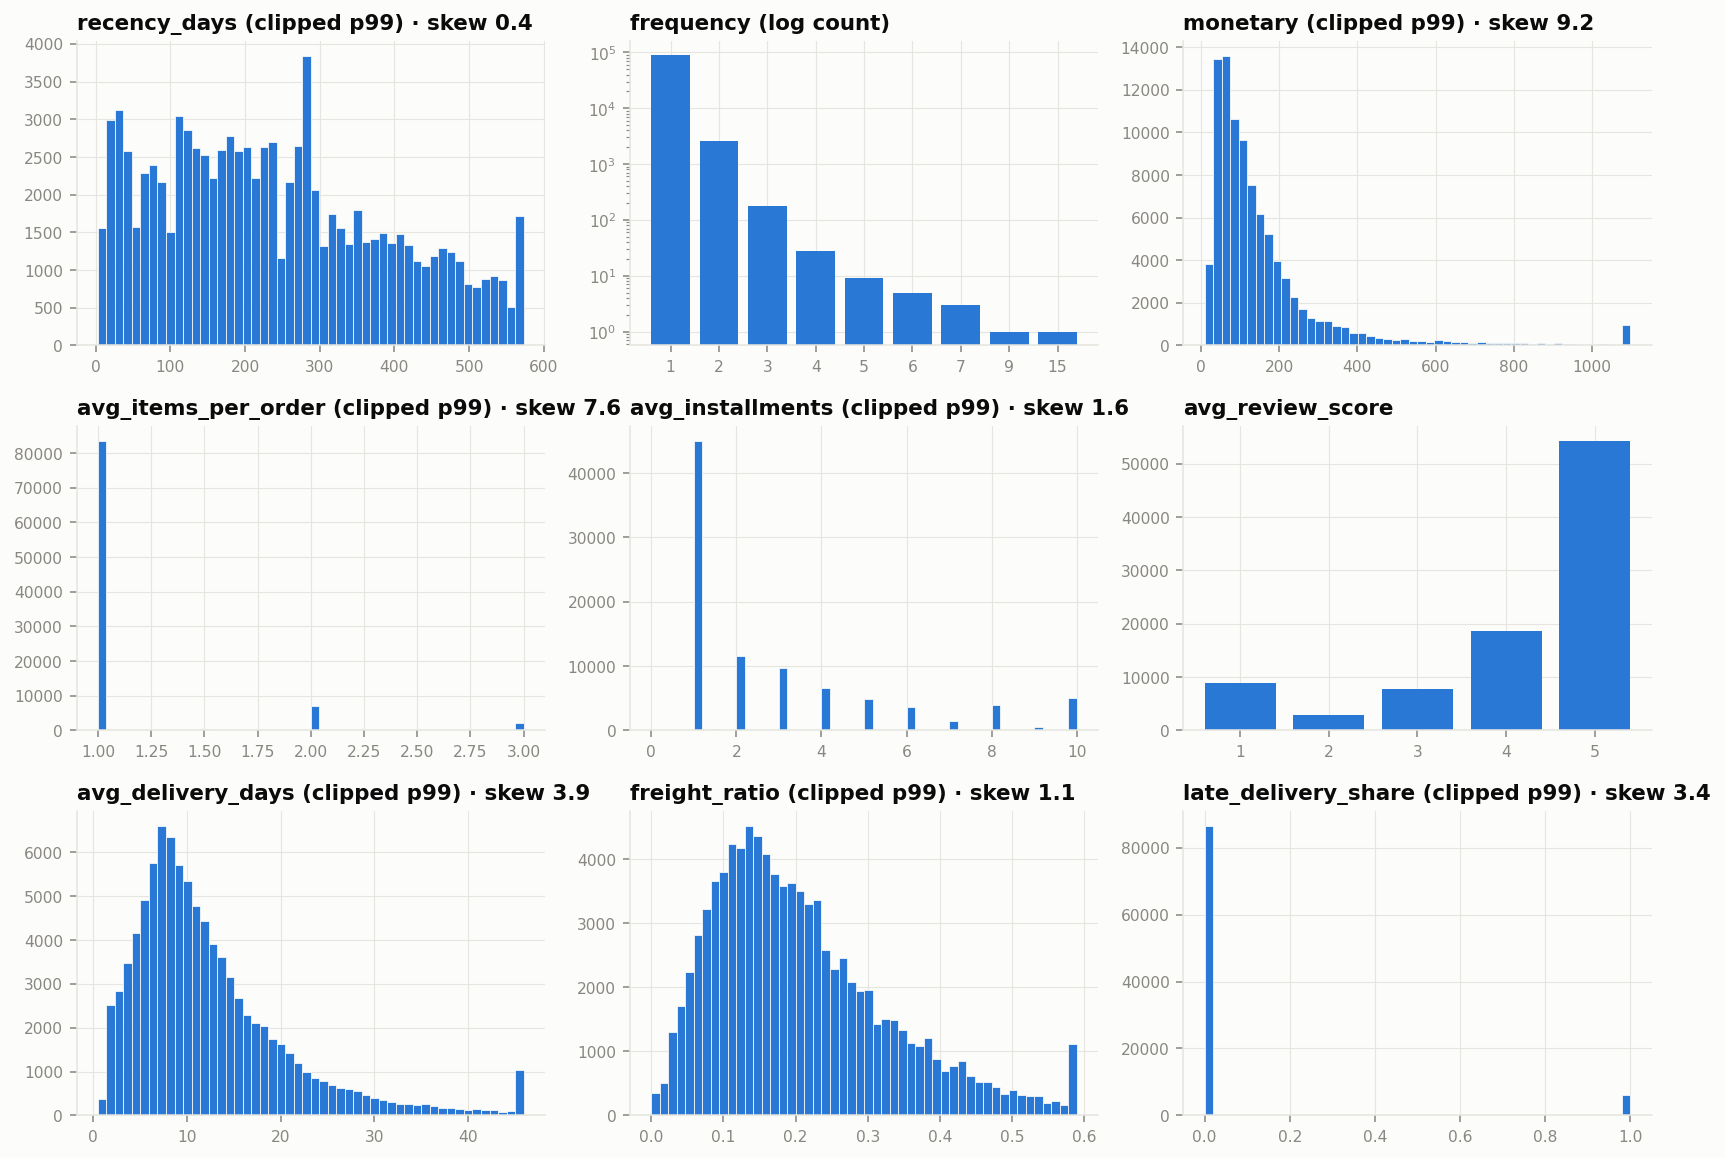

In [3]:
img('04_data_profiling_eda/reports/figures/univariate_distributions.png')

In [4]:
db.query("SELECT frequency, count(*) customers FROM mart.customer_rfm GROUP BY 1 ORDER BY 1")

,frequency,customers
0,1,90315
1,2,2562
2,3,180
3,4,28
4,5,9
5,6,5
6,7,3
7,9,1
8,15,1


97 % of customers have exactly one delivered order; monetary is strongly right-skewed.